<a href="https://colab.research.google.com/github/Shivaji-Vasanth/Deep-Learning/blob/main/Exp9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 9: Multilayer Perceptron Implementation

**Problem Statement:** A telecom operator wants to predict which customers will cancel their subscription next month. A customer-churn dataset with tenure, monthly charges, contract type, complaints and data usage, with a Churn label. The objective is to build, train and evaluate an MLP classifier in Keras. Use TensorFlow, Keras, NumPy, Matplotlib.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)
print("Libraries imported successfully.")

Libraries imported successfully.


## Step 1: Generate Simulated Dataset & Pre-process
We will simulate a dataset with 2000 customers containing:
* Numerical: `tenure` (months), `monthly_charges` ($), `data_usage` (GB)
* Categorical: `contract_type` (Month-to-month, One year, Two year), `complaints` (Yes, No)
* Target: `Churn` (0 or 1)

In [2]:
# Generate simulated data
n_samples = 2000
tenure = np.random.randint(1, 72, size=n_samples)
monthly_charges = np.random.uniform(20, 120, size=n_samples)
data_usage = np.random.uniform(0, 500, size=n_samples)
contract_type = np.random.choice(['Month-to-month', 'One year', 'Two year'], size=n_samples, p=[0.5, 0.3, 0.2])
complaints = np.random.choice(['Yes', 'No'], size=n_samples, p=[0.3, 0.7])

# Create a basic rule to make Churn semi-realistic
# High complaints, short tenure, high monthly charges, and month-to-month contract increase churn probability
churn_prob = (0.3 * (complaints == 'Yes') +
              0.2 * (contract_type == 'Month-to-month') +
              0.2 * (monthly_charges > 80) -
              0.3 * (tenure > 30) / 72.0)

churn_prob = np.clip(churn_prob + 0.2, 0, 1)
churn = np.random.binomial(1, churn_prob)

# Construct DataFrame
df = pd.DataFrame({
    'tenure': tenure,
    'monthly_charges': monthly_charges,
    'data_usage': data_usage,
    'contract_type': contract_type,
    'complaints': complaints,
    'Churn': churn
})

# Split into features and target
X = df.drop(columns=['Churn'])
y = df['Churn'].values

# Split into Train and Test sets
X_train_raw, X_test_raw, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Preprocessing pipeline
num_cols = ['tenure', 'monthly_charges', 'data_usage']
cat_cols = ['contract_type', 'complaints']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(drop='first'), cat_cols)
    ])

X_train = preprocessor.fit_transform(X_train_raw)
X_test = preprocessor.transform(X_test_raw)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
display(df.head())

X_train shape: (1600, 6)
X_test shape: (400, 6)


,tenure,monthly_charges,data_usage,contract_type,complaints,Churn
0,52,45.467062,328.515249,Two year,No,0
1,15,104.087158,449.193233,Month-to-month,No,0
2,61,23.842635,199.759392,One year,No,0
3,21,110.176199,163.397353,Month-to-month,Yes,1
4,24,66.147746,5.405542,One year,No,0


## Step 2 & 3: Build, Train, and Plot Training Performance of the Base MLP

In [3]:
def build_mlp(input_dim, hidden_units=[64, 32]):
    model = keras.Sequential()
    model.add(layers.Input(shape=(input_dim,)))
    for units in hidden_units:
        model.add(layers.Dense(units, activation='relu'))
    model.add(layers.Dense(1, activation='sigmoid'))

    model.compile(optimizer='adam',
                  loss='binary_crossentropy',
                  metrics=['accuracy'])
    return model

# Build the base model
model = build_mlp(X_train.shape[1], hidden_units=[64, 32])
model.summary()

# Train the model
history = model.fit(X_train, y_train,
                    validation_split=0.2,
                    epochs=40,
                    batch_size=32,
                    verbose=1)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,561 (10.00 KB)

 Trainable params: 2,561 (10.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
40/40 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - accuracy: 0.5883 - loss: 0.6721 - val_accuracy: 0.6531 - val_loss: 0.6477
Epoch 2/40
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.6375 - loss: 0.6355 - val_accuracy: 0.6719 - val_loss: 0.6218
Epoch 3/40
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.6477 - loss: 0.6178 - val_accuracy: 0.6656 - val_loss: 0.6113
Epoch 4/40
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.6523 - loss: 0.6094 - val_accuracy: 0.6594 - val_loss: 0.6075
Epoch 5/40
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6578 - loss: 0.6050 - val_accuracy: 0.6531 - val_loss: 0.6065
Epoch 6/40
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.6625 - loss: 0.6022 - val_accuracy: 0.6531 - val_loss: 0.6065
Epoch 7/40
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6656 - loss: 0.6000 - val_accuracy: 0.6562 - val_loss: 0.6066
Epoch 8/40
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6664 - loss: 0.5983 - val_accuracy: 0.6562 - val_los

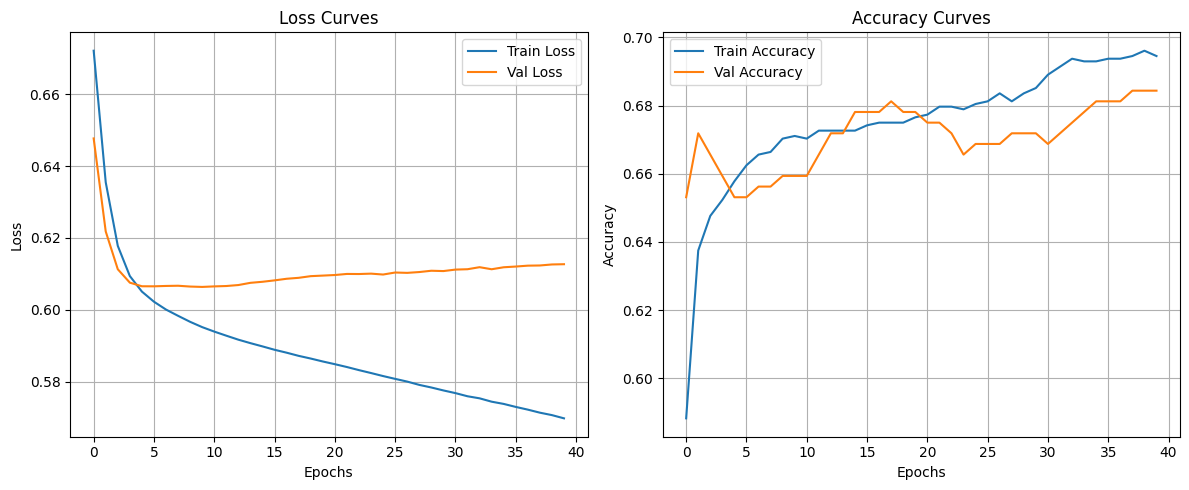

In [4]:
# Plot training and validation curves
plt.figure(figsize=(12, 5))

# Plot Loss
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Loss Curves')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Plot Accuracy
plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Accuracy Curves')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

## Step 4: Evaluate Model Performance
We will evaluate accuracy, precision, recall, F1-score, and display the confusion matrix.

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
--- Base Model Evaluation [64, 32] ---
Accuracy:  0.6575
Precision: 0.6667
Recall:    0.5654
F1-Score:  0.6119


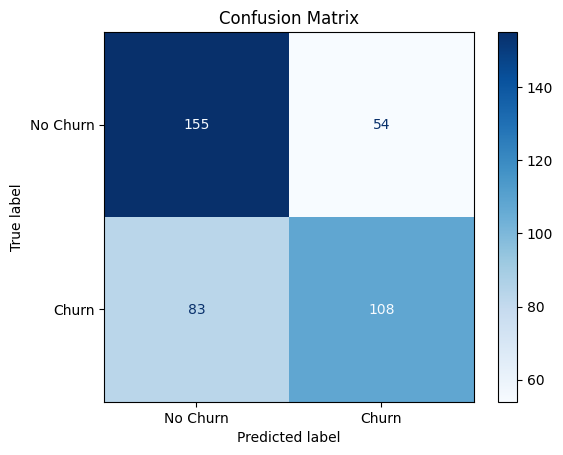

In [5]:
# Predict probabilities and convert to binary classes
y_pred_prob = model.predict(X_test)
y_pred = (y_pred_prob > 0.5).astype(int).flatten()

# Compute metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"--- Base Model Evaluation [64, 32] ---")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")

# Plot Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Churn', 'Churn'])
disp.plot(cmap='Blues')
plt.title("Confusion Matrix")
plt.show()

## Step 5: Vary Hidden-Layer Width and Observe Effects

In [6]:
architectures = {
    "Narrow [16, 8]": [16, 8],
    "Medium [64, 32]": [64, 32],
    "Wide [128, 64]": [128, 64],
    "Deep & Wide [256, 128, 64]": [256, 128, 64]
}

results = {}

for name, config in architectures.items():
    print(f"\nTraining configuration: {name}")
    temp_model = build_mlp(X_train.shape[1], hidden_units=config)
    temp_history = temp_model.fit(X_train, y_train,
                                  epochs=30,
                                  batch_size=32,
                                  verbose=0,
                                  validation_split=0.2)

    preds = (temp_model.predict(X_test) > 0.5).astype(int).flatten()

    results[name] = {
        'accuracy': accuracy_score(y_test, preds),
        'f1_score': f1_score(y_test, preds),
        'val_loss_final': temp_history.history['val_loss'][-1]
    }

# Display summary of results
results_df = pd.DataFrame(results).T
display(results_df)


Training configuration: Narrow [16, 8]
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 

Training configuration: Medium [64, 32]
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 

Training configuration: Wide [128, 64]
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 

Training configuration: Deep & Wide [256, 128, 64]
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step


,accuracy,f1_score,val_loss_final
"Narrow [16, 8]",0.6625,0.623955,0.606823
"Medium [64, 32]",0.6625,0.619718,0.611065
"Wide [128, 64]",0.6350,0.582857,0.609412
"Deep & Wide [256, 128, 64]",0.6200,0.568182,0.612122
